# Yaku: Limpieza y Análisis Exploratorio de los Sensores (Base de Datos)

Este notebook toma las lecturas **reales** de los 4 sensores almacenadas en PostgreSQL (`YakuDB`), las limpia y grafica solo los datos válidos:

| Sensor | Tabla | Columna |
|---|---|---|
| Humedad del suelo (capacitivo) | `humedad_suelo` | `porcentaje` |
| Humedad ambiente (DHT22) | `humedad_ambiente` | `porcentaje` |
| Temperatura ambiente (DHT22) | `temperatura_ambiente` | `temperatura` |
| Temperatura del suelo (DS18B20) | `temperatura_suelo` | `temperatura` |

**Proceso:**
1. Carga de lecturas reales. Se excluyen los datos sintéticos de `datos_proyeccion_14_27_sep.sql`.
2. Limpieza: lecturas inválidas, valores fuera de rango físico y valores atípicos.
3. Análisis exploratorio sobre los datos limpios. Los periodos sin transmisión se dejan en blanco y no se rellenan.

Las credenciales se leen del archivo `.env` del backend (`DB_HOST`, `DB_PORT`, `DB_NAME`, `DB_USER`, `DB_PASSWORD`).

## 0. Preparación del entorno
Si faltan librerías: `pip install pandas numpy sqlalchemy psycopg2-binary python-dotenv matplotlib seaborn`

In [22]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import dotenv_values
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# Busca el .env del backend (el que tiene DB_HOST) sin depender de la carpeta
# desde donde se abrió Jupyter: Yaku-Backend/, la raíz del repo o una subcarpeta.
candidatos = [Path.cwd() / ".env", Path.cwd() / "Yaku-Backend" / ".env"]
candidatos += [p / ".env" for p in Path.cwd().parents]
candidatos += [p / "Yaku-Backend" / ".env" for p in Path.cwd().parents]
env_path = next((p for p in candidatos if p.is_file() and dotenv_values(p).get("DB_HOST")), None)
if env_path is None:
    raise FileNotFoundError("No se encontró un .env con DB_HOST. Abre el notebook desde Yaku-Backend/.")
env = dotenv_values(env_path)

engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username=env.get("DB_USER"),
    password=env.get("DB_PASSWORD"),
    host=env.get("DB_HOST"),
    port=int(env.get("DB_PORT") or 5432),
    database=env.get("DB_NAME") or "YakuDB",
), connect_args={"connect_timeout": 10})

with engine.connect() as conn:
    conn.execute(text("SELECT 1"))
print(f"Conectado a {env.get('DB_HOST')}:{env.get('DB_PORT')}/{env.get('DB_NAME')} (credenciales de {env_path})")

Conectado a 192.168.0.200:5433/YakuDB (credenciales de c:\Archivos\Code\Yaku-Backend\.env)


## 1. Parámetros y carga de datos

- `FECHA_INICIO` / `FECHA_FIN` / `ID_CULTIVO`: filtros opcionales; `None` significa sin filtro.
- `rango`: límites físicos del sensor. En las humedades, los extremos son topes de calibración (sensor desconectado, fuera de la tierra o saturado) y no medidas reales, así que los valores que llegan al límite también se descartan. En la humedad del suelo se toma un margen de 1 %, porque cerca de 0 % y 100 % el sensor solo da ruido (0,01 %, 99,9 %).
- `tolerancia`: variación mínima que el filtro de atípicos local considera un pico.

In [23]:
FECHA_INICIO = None   # ej. "2026-09-29"
FECHA_FIN = None      # ej. "2026-10-02" (inclusive)
ID_CULTIVO = None     # ej. 2

# Datos sintéticos insertados por src/resources/datos_proyeccion_14_27_sep.sql:
# están en este rango (UTC) y sus fechas no tienen microsegundos; las lecturas reales sí.
SINTETICOS_DESDE = "2026-09-14 05:00:00"
SINTETICOS_HASTA = "2026-09-28 05:00:00"

HUECO_MAXIMO = pd.Timedelta("10min")   # más tiempo sin lecturas = periodo sin datos
VENTANA_HAMPEL = "15min"               # ventana del filtro de picos
K_HAMPEL = 3                           # nº de desviaciones robustas para considerar pico
K_IQR = 1.5                            # Tukey: 1.5*IQR, igual que los bigotes del boxplot

SENSORES = {
    "humedad_suelo":        {"columna": "porcentaje",  "titulo": "Humedad del Suelo",     "unidad": "%",  "color": "#2b5c8f",
                             "rango": (1, 99),  "excluir_limites": True,  "tolerancia": 2.0},
    "humedad_ambiente":     {"columna": "porcentaje",  "titulo": "Humedad Ambiental",     "unidad": "%",  "color": "#3a9e7a",
                             "rango": (0, 100), "excluir_limites": True,  "tolerancia": 2.0},
    "temperatura_ambiente": {"columna": "temperatura", "titulo": "Temperatura Ambiental", "unidad": "°C", "color": "#d95d39",
                             "rango": (-5, 50), "excluir_limites": False, "tolerancia": 0.5},
    "temperatura_suelo":    {"columna": "temperatura", "titulo": "Temperatura del Suelo", "unidad": "°C", "color": "#8e5ea2",
                             "rango": (-5, 50), "excluir_limites": False, "tolerancia": 0.5},
}
etiquetas = {tabla: cfg["titulo"] for tabla, cfg in SENSORES.items()}

def cargar_sensor(tabla, columna):
    filtros = [
        "NOT (t.fecha >= :sint_desde AND t.fecha < :sint_hasta AND t.fecha = date_trunc('second', t.fecha))"
    ]
    params = {"sint_desde": SINTETICOS_DESDE, "sint_hasta": SINTETICOS_HASTA}
    if FECHA_INICIO:
        filtros.append("t.fecha >= :inicio")
        params["inicio"] = FECHA_INICIO
    if FECHA_FIN:
        filtros.append("t.fecha < CAST(:fin AS date) + 1")
        params["fin"] = FECHA_FIN
    if ID_CULTIVO is not None:
        filtros.append("a.id_cultivo = :cultivo")
        params["cultivo"] = ID_CULTIVO
    sql = f"""
        SELECT t.fecha,
               COALESCE(t.{columna}, t.valor)::float AS valor,
               COALESCE(t.valido, TRUE) AS valido,
               a.id_cultivo,
               c.nombre_planta AS cultivo
        FROM {tabla} t
        JOIN asignaciones_iot a ON a.id = t.id_asignacion
        LEFT JOIN cultivos c     ON c.id = a.id_cultivo
        WHERE {' AND '.join(filtros)}
        ORDER BY t.fecha
    """
    with engine.connect() as conn:
        df = pd.read_sql(text(sql), conn, params=params, parse_dates=["fecha"])
    df["sensor"] = tabla
    return df

crudas = pd.concat(
    [cargar_sensor(tabla, cfg["columna"]) for tabla, cfg in SENSORES.items()],
    ignore_index=True,
)
crudas.groupby("sensor").agg(
    lecturas_reales=("valor", "size"), desde=("fecha", "min"), hasta=("fecha", "max")
).rename(index=etiquetas)

,lecturas_reales,desde,hasta
sensor,,,
Humedad Ambiental,3781,2026-09-29 02:01:29.656097,2026-10-02 18:39:24.486935
Humedad del Suelo,3781,2026-09-29 02:01:29.647603,2026-10-02 18:39:24.483433
Temperatura Ambiental,3781,2026-09-29 02:01:29.662671,2026-10-02 18:39:24.489790
Temperatura del Suelo,3781,2026-09-29 02:01:29.669170,2026-10-02 18:39:24.492657


## 2. Limpieza de datos

Cada lectura se marca con el **primer** motivo de descarte que cumpla, en este orden:

1. **Sin valor:** el valor es nulo.
2. **Inválida (firmware):** el ESP32 o el backend la guardó con `valido = false`.
3. **Fuera de rango físico:** el valor es imposible para el sensor o está pegado a un tope de calibración.
4. **Sonda fuera del suelo:** si en un minuto la humedad del suelo llega a su tope inferior (sonda al aire), la temperatura del suelo de ese minuto tampoco mide el suelo, porque ambas sondas van enterradas juntas. Se descarta.
5. **Pico (Hampel):** la lectura se aleja de la mediana de los ±7,5 minutos vecinos más de `K_HAMPEL` desviaciones robustas (MAD) y más que la `tolerancia` del sensor. Así se quitan los saltos aislados sin borrar los cambios reales de nivel, como después de un riego.
6. **Atípico (IQR):** el valor queda fuera de `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]` del sensor (criterio de Tukey).

In [24]:
lecturas = crudas.copy()
lecturas["motivo"] = pd.Series(pd.NA, index=lecturas.index, dtype="string")

def marcar(mascara, motivo):
    lecturas.loc[mascara & lecturas["motivo"].isna(), "motivo"] = motivo

# 1-2. Nulos e inválidas
marcar(lecturas["valor"].isna(), "Sin valor")
marcar(~lecturas["valido"].astype(bool), "Inválida (firmware)")

# 3. Rango físico
for tabla, cfg in SENSORES.items():
    lo, hi = cfg["rango"]
    v = lecturas["valor"]
    fuera = (v <= lo) | (v >= hi) if cfg["excluir_limites"] else (v < lo) | (v > hi)
    marcar((lecturas["sensor"] == tabla) & fuera, "Fuera de rango físico")

# 4. Sonda fuera del suelo: humedad del suelo en su tope inferior => la temperatura
#    del suelo de ese mismo minuto mide el aire, no el suelo
minuto = lecturas["fecha"].dt.floor("min")
lo_suelo = SENSORES["humedad_suelo"]["rango"][0]
al_aire = minuto[(lecturas["sensor"] == "humedad_suelo") & (lecturas["valor"] <= lo_suelo)]
marcar((lecturas["sensor"] == "temperatura_suelo") & minuto.isin(set(al_aire)), "Sonda fuera del suelo")

# 5. Picos locales (filtro de Hampel sobre ventana de tiempo)
for tabla, cfg in SENSORES.items():
    sub = lecturas[(lecturas["sensor"] == tabla) & lecturas["motivo"].isna()].sort_values("fecha")
    s = pd.Series(sub["valor"].to_numpy(), index=sub["fecha"])
    mediana = s.rolling(VENTANA_HAMPEL, center=True, min_periods=5).median()
    desvio = (s - mediana).abs()
    mad = desvio.rolling(VENTANA_HAMPEL, center=True, min_periods=5).median()
    umbral = np.maximum(K_HAMPEL * 1.4826 * mad, cfg["tolerancia"])
    pico = (desvio > umbral).to_numpy()
    lecturas.loc[sub.index[pico], "motivo"] = "Pico (Hampel)"

# 6. Atípicos (IQR de Tukey)
limites_iqr = {}
for tabla in SENSORES:
    m = (lecturas["sensor"] == tabla) & lecturas["motivo"].isna()
    q1, q3 = lecturas.loc[m, "valor"].quantile([0.25, 0.75])
    lo, hi = q1 - K_IQR * (q3 - q1), q3 + K_IQR * (q3 - q1)
    limites_iqr[etiquetas[tabla]] = (round(lo, 2), round(hi, 2))
    marcar(m & ((lecturas["valor"] < lo) | (lecturas["valor"] > hi)), "Atípico (IQR)")

lecturas["motivo"] = lecturas["motivo"].fillna("Conservada")
limpias = lecturas[lecturas["motivo"] == "Conservada"].copy()

print("Límites IQR aplicados:", limites_iqr)

Límites IQR aplicados: {'Humedad del Suelo': (33.35, 129.17), 'Humedad Ambiental': (81.25, 104.85), 'Temperatura Ambiental': (23.14, 24.62), 'Temperatura del Suelo': (22.62, 23.74)}


### 2.1 Resumen de la limpieza

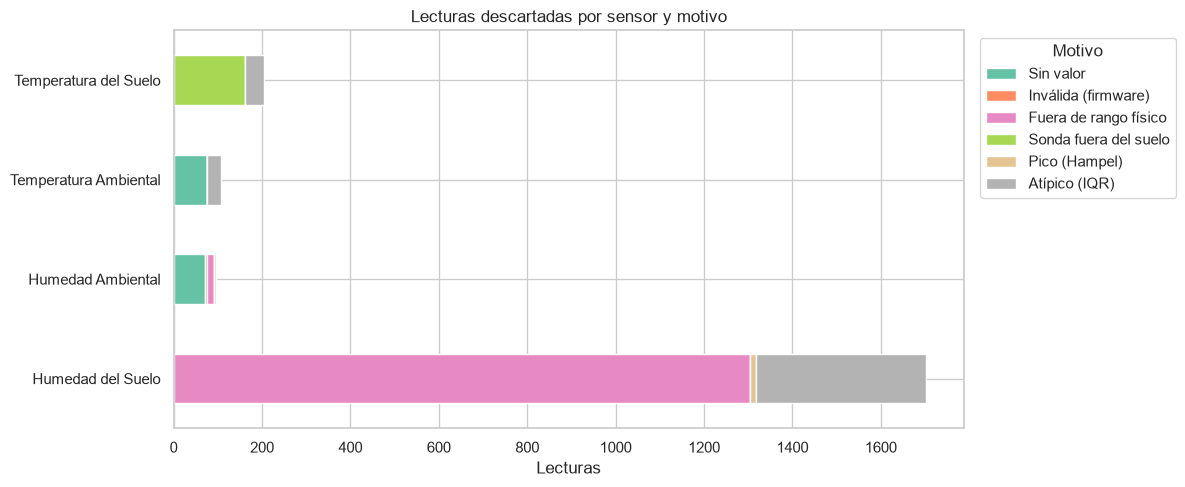

motivo,Sin valor,Inválida (firmware),Fuera de rango físico,Sonda fuera del suelo,Pico (Hampel),Atípico (IQR),Conservada,Total,% descartado
sensor,,,,,,,,,
Humedad del Suelo,1,0,1304,0,13,385,2078,3781,45.04
Humedad Ambiental,72,3,16,0,5,0,3685,3781,2.54
Temperatura Ambiental,75,0,0,0,1,31,3674,3781,2.83
Temperatura del Suelo,0,0,0,161,1,43,3576,3781,5.42


In [25]:
ORDEN_MOTIVOS = ["Sin valor", "Inválida (firmware)", "Fuera de rango físico",
                 "Sonda fuera del suelo", "Pico (Hampel)", "Atípico (IQR)", "Conservada"]
resumen = (
    pd.crosstab(lecturas["sensor"], lecturas["motivo"])
    .reindex(index=list(SENSORES), columns=ORDEN_MOTIVOS, fill_value=0)
)
resumen["Total"] = resumen.sum(axis=1)
resumen["% descartado"] = (100 * (1 - resumen["Conservada"] / resumen["Total"])).round(2)

descartes = resumen[ORDEN_MOTIVOS[:-1]].rename(index=etiquetas)
ax = descartes.plot(kind="barh", stacked=True, figsize=(12, 5), colormap="Set2")
ax.set_title("Lecturas descartadas por sensor y motivo", fontsize=12)
ax.set_xlabel("Lecturas")
ax.set_ylabel("")
ax.legend(title="Motivo", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

resumen.rename(index=etiquetas)

### 2.2 Antes y después de la limpieza
El boxplot de la izquierda incluye todas las lecturas reales y el de la derecha solo las conservadas.

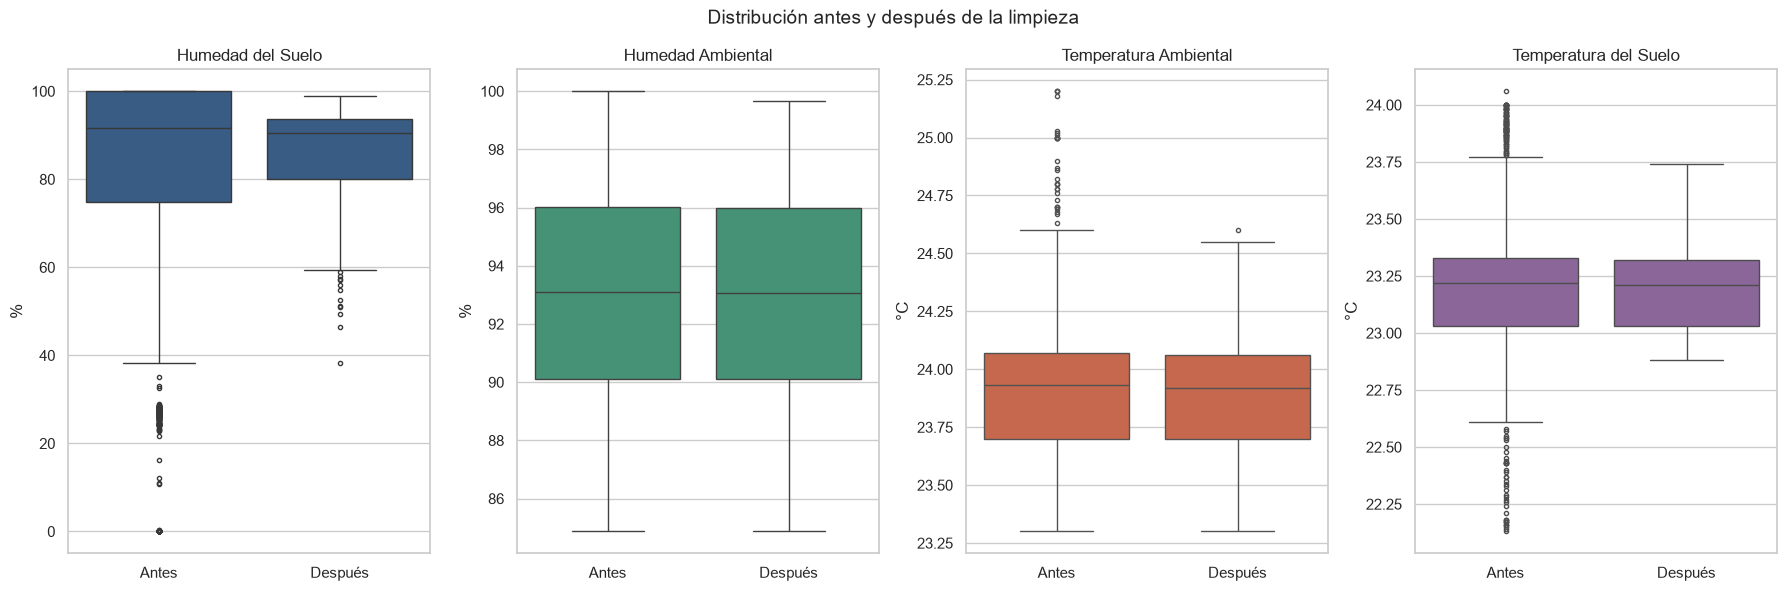

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(18, 6))
for ax, (tabla, cfg) in zip(axes, SENSORES.items()):
    antes = crudas.loc[crudas["sensor"] == tabla, "valor"].dropna()
    despues = limpias.loc[limpias["sensor"] == tabla, "valor"]
    comp = pd.DataFrame({
        "Etapa": ["Antes"] * len(antes) + ["Después"] * len(despues),
        "valor": np.concatenate([antes.to_numpy(), despues.to_numpy()]),
    })
    sns.boxplot(data=comp, x="Etapa", y="valor", ax=ax, color=cfg["color"], fliersize=3)
    ax.set_title(cfg["titulo"], fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel(cfg["unidad"])
plt.suptitle("Distribución antes y después de la limpieza", fontsize=14)
plt.tight_layout()
plt.show()

### 2.3 Periodos sin datos
Intervalos de más de `HUECO_MAXIMO` sin lecturas del dispositivo. Estos periodos **no se rellenan ni se interpolan**: en las gráficas aparecen en blanco.

In [27]:
marcas = crudas["fecha"].drop_duplicates().sort_values()
salto = marcas.diff()
huecos = pd.DataFrame({
    "desde": marcas.shift(1)[salto > HUECO_MAXIMO],
    "hasta": marcas[salto > HUECO_MAXIMO],
})
huecos["duración"] = huecos["hasta"] - huecos["desde"]
print(f"Periodos sin datos: {len(huecos)} | tiempo total sin datos: {huecos['duración'].sum()}")
huecos.reset_index(drop=True)

Periodos sin datos: 8 | tiempo total sin datos: 0 days 23:46:09.012097


,desde,hasta,duración
0,2026-09-29 02:03:32.811463,2026-09-29 02:13:43.761792,0 days 00:10:10.950329
1,2026-09-29 02:19:02.140210,2026-09-29 04:15:21.776223,0 days 01:56:19.636013
2,2026-09-29 04:27:36.099408,2026-09-29 04:37:40.879330,0 days 00:10:04.779922
3,2026-09-29 04:45:53.583009,2026-09-29 04:56:40.639950,0 days 00:10:47.056941
4,2026-09-29 05:43:41.889898,2026-09-29 17:23:35.515639,0 days 11:39:53.625741
5,2026-09-29 17:33:23.866630,2026-09-29 17:43:45.918327,0 days 00:10:22.051697
6,2026-09-30 22:32:21.366190,2026-09-30 22:49:45.870296,0 days 00:17:24.504106
7,2026-10-01 07:01:28.160030,2026-10-01 16:12:34.567378,0 days 09:11:06.407348


### 2.4 Tabla de datos limpios (una columna por sensor)
Las 4 lecturas de un mismo envío llegan con milisegundos de diferencia, así que se alinean por minuto para poder cruzarlas.

In [28]:
datos = (
    limpias.assign(fecha=limpias["fecha"].dt.floor("min"))
    .pivot_table(index="fecha", columns="sensor", values="valor", aggfunc="mean")
    .reindex(columns=list(SENSORES))
)

def con_cortes(serie):
    """Inserta NaN donde no hubo lecturas para que matplotlib no una los puntos a través del hueco."""
    serie = serie.dropna()
    saltos = serie.index.to_series().diff() > HUECO_MAXIMO
    vacios = pd.Series(np.nan, index=serie.index[saltos] - pd.Timedelta("1s"))
    return pd.concat([serie, vacios]).sort_index()

print(f"Registros limpios alineados: {len(datos)}")
datos.head()

Registros limpios alineados: 3740


sensor,humedad_suelo,humedad_ambiente,temperatura_ambiente,temperatura_suelo
fecha,,,,
2026-09-29 02:01:00,65.23,85.97,NaN,23.31
2026-09-29 02:02:00,65.44,85.76,NaN,23.31
2026-09-29 02:03:00,65.67,85.87,NaN,23.31
2026-09-29 02:13:00,NaN,NaN,NaN,23.31
2026-09-29 02:15:00,62.24,NaN,NaN,23.31


## 3. Estadísticas descriptivas (datos limpios)

In [ ]:
datos.rename(columns=etiquetas).describe().T.round(2)

## 4. Distribución de cada sensor

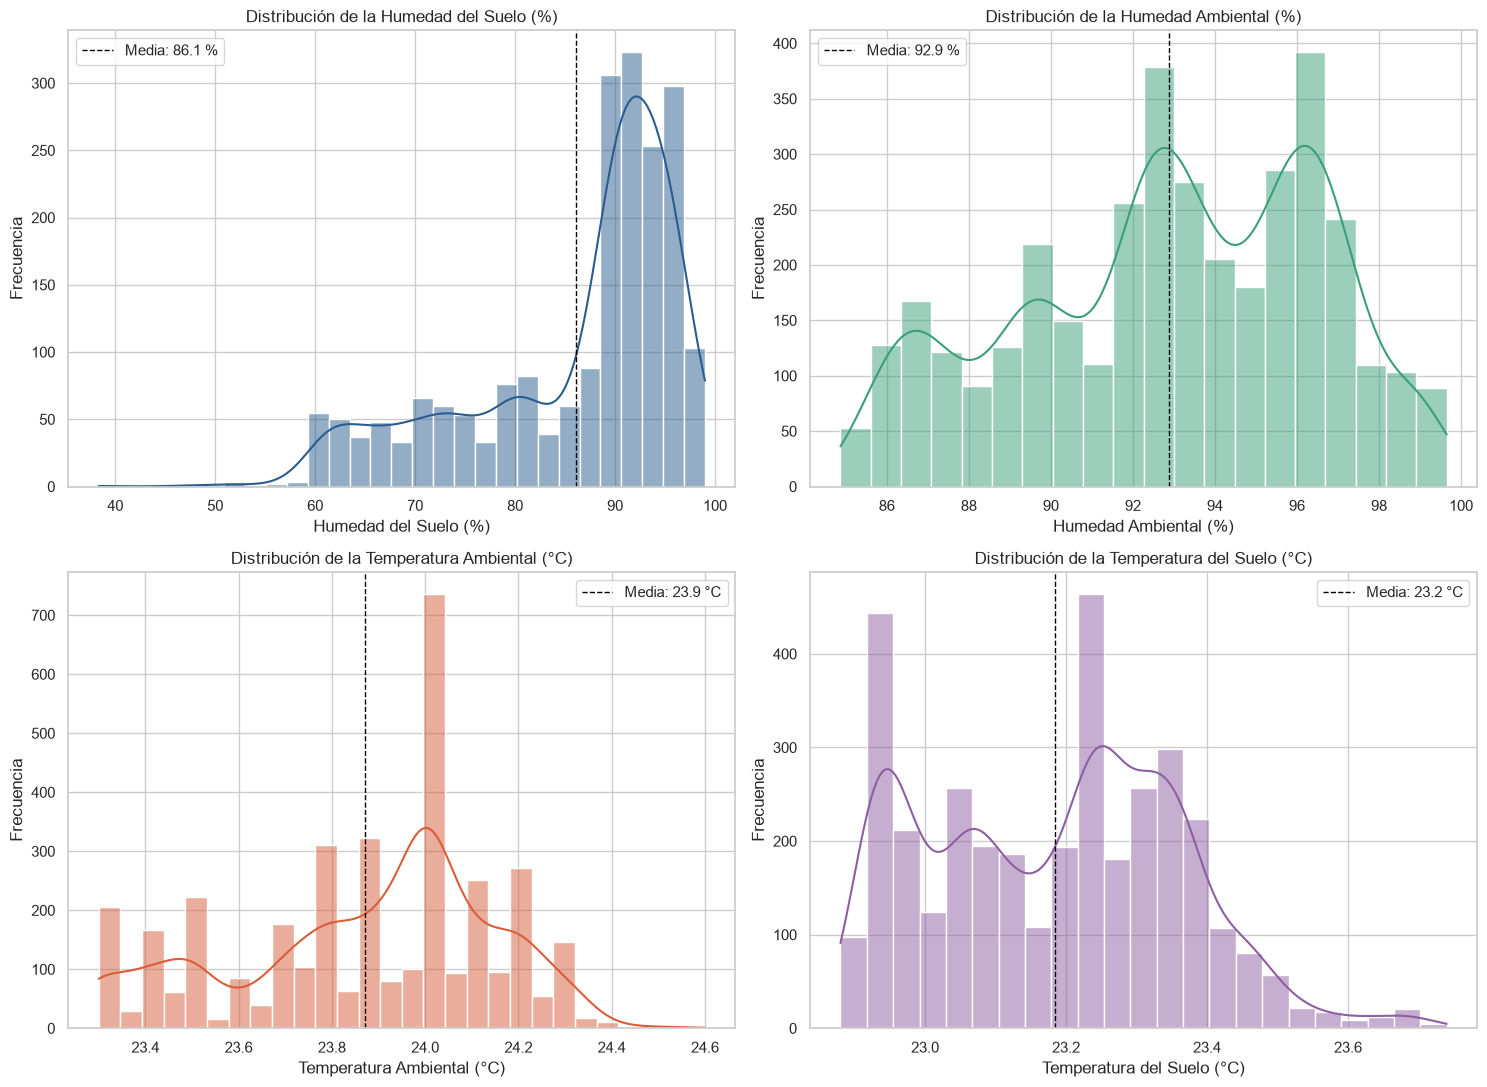

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, (tabla, cfg) in zip(axes.flat, SENSORES.items()):
    serie = datos[tabla].dropna()
    sns.histplot(serie, kde=True, ax=ax, color=cfg["color"])
    ax.axvline(serie.mean(), color="black", linestyle="--", linewidth=1,
               label=f"Media: {serie.mean():.1f} {cfg['unidad']}")
    ax.set_title(f"Distribución de la {cfg['titulo']} ({cfg['unidad']})", fontsize=12)
    ax.set_xlabel(f"{cfg['titulo']} ({cfg['unidad']})")
    ax.set_ylabel("Frecuencia")
    ax.legend()
plt.tight_layout()
plt.show()

## 5. Series de tiempo
Muestra las lecturas limpias (línea tenue) y su promedio horario (línea fuerte). Los periodos sin datos quedan en blanco.

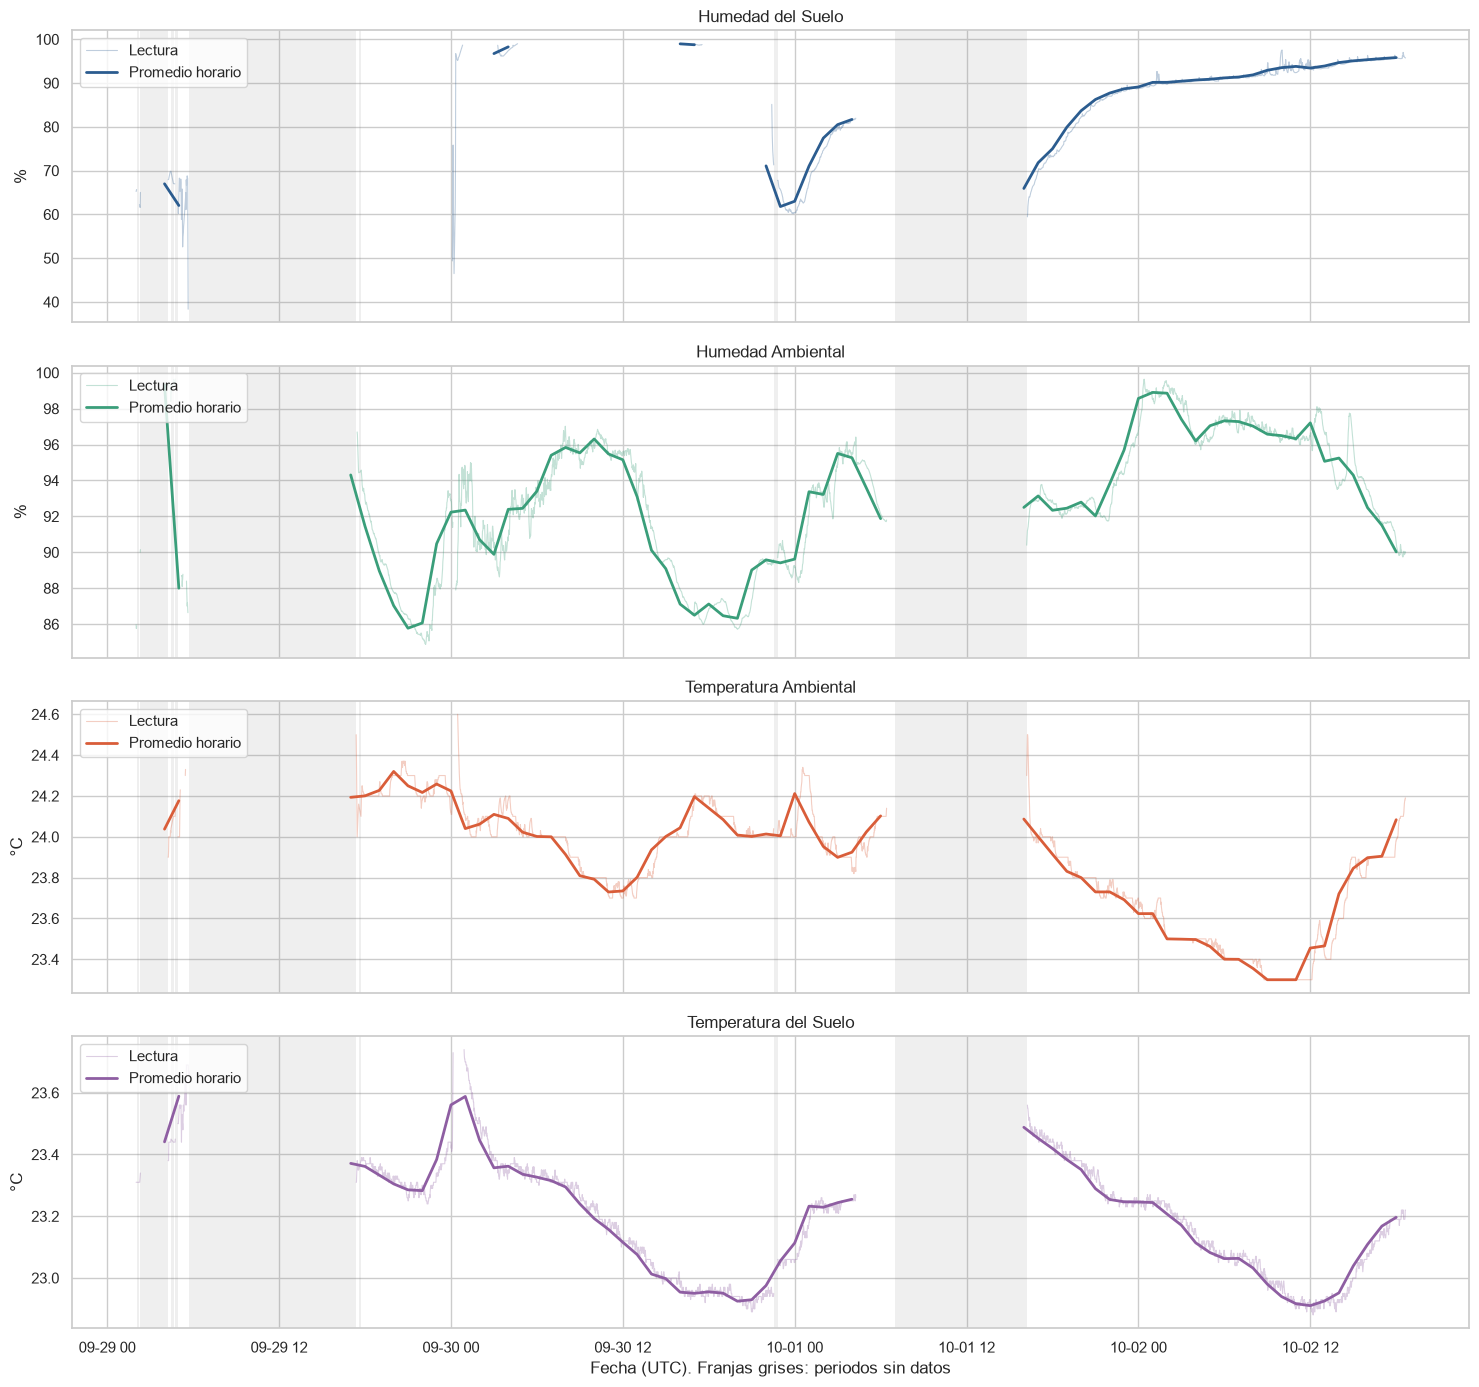

In [30]:
fig, axes = plt.subplots(4, 1, figsize=(15, 14), sharex=True)
for ax, (tabla, cfg) in zip(axes, SENSORES.items()):
    serie = con_cortes(datos[tabla])
    ax.plot(serie.index, serie.values, color=cfg["color"], alpha=0.3, linewidth=0.8, label="Lectura")
    horaria = datos[tabla].resample("1h").mean()   # horas sin lecturas quedan en NaN
    ax.plot(horaria.index, horaria.values, color=cfg["color"], linewidth=2, label="Promedio horario")
    for _, h in huecos.iterrows():
        ax.axvspan(h["desde"], h["hasta"], color="grey", alpha=0.12, linewidth=0)
    ax.set_title(cfg["titulo"], fontsize=12)
    ax.set_ylabel(cfg["unidad"])
    ax.legend(loc="upper left")
axes[-1].set_xlabel("Fecha (UTC). Franjas grises: periodos sin datos")
plt.tight_layout()
plt.show()

## 6. Variación diaria (boxplot por día)

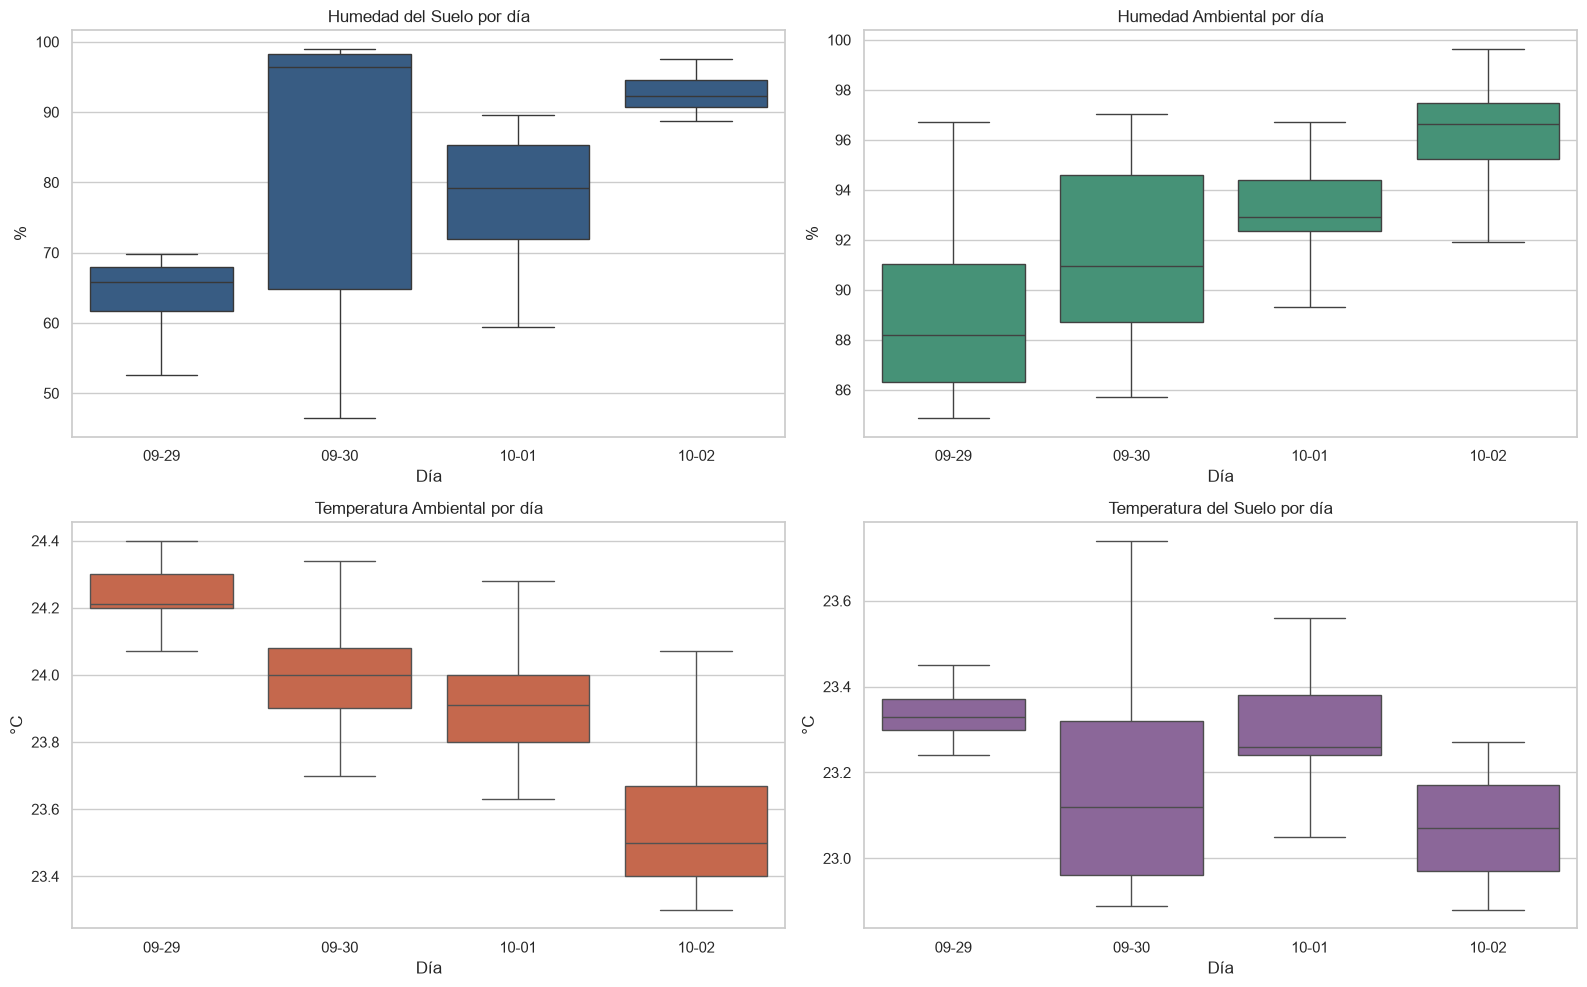

In [31]:
por_dia = datos.reset_index().melt(id_vars="fecha", var_name="sensor", value_name="valor").dropna()
por_dia["dia"] = por_dia["fecha"].dt.strftime("%m-%d")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, (tabla, cfg) in zip(axes.flat, SENSORES.items()):
    sns.boxplot(data=por_dia[por_dia["sensor"] == tabla], x="dia", y="valor", ax=ax,
                color=cfg["color"], showfliers=False)
    ax.set_title(f"{cfg['titulo']} por día", fontsize=12)
    ax.set_xlabel("Día")
    ax.set_ylabel(cfg["unidad"])
plt.tight_layout()
plt.show()

## 7. Perfil promedio por hora del día
Media ± desviación estándar según la hora (UTC). Solo se muestran las horas que tienen lecturas.

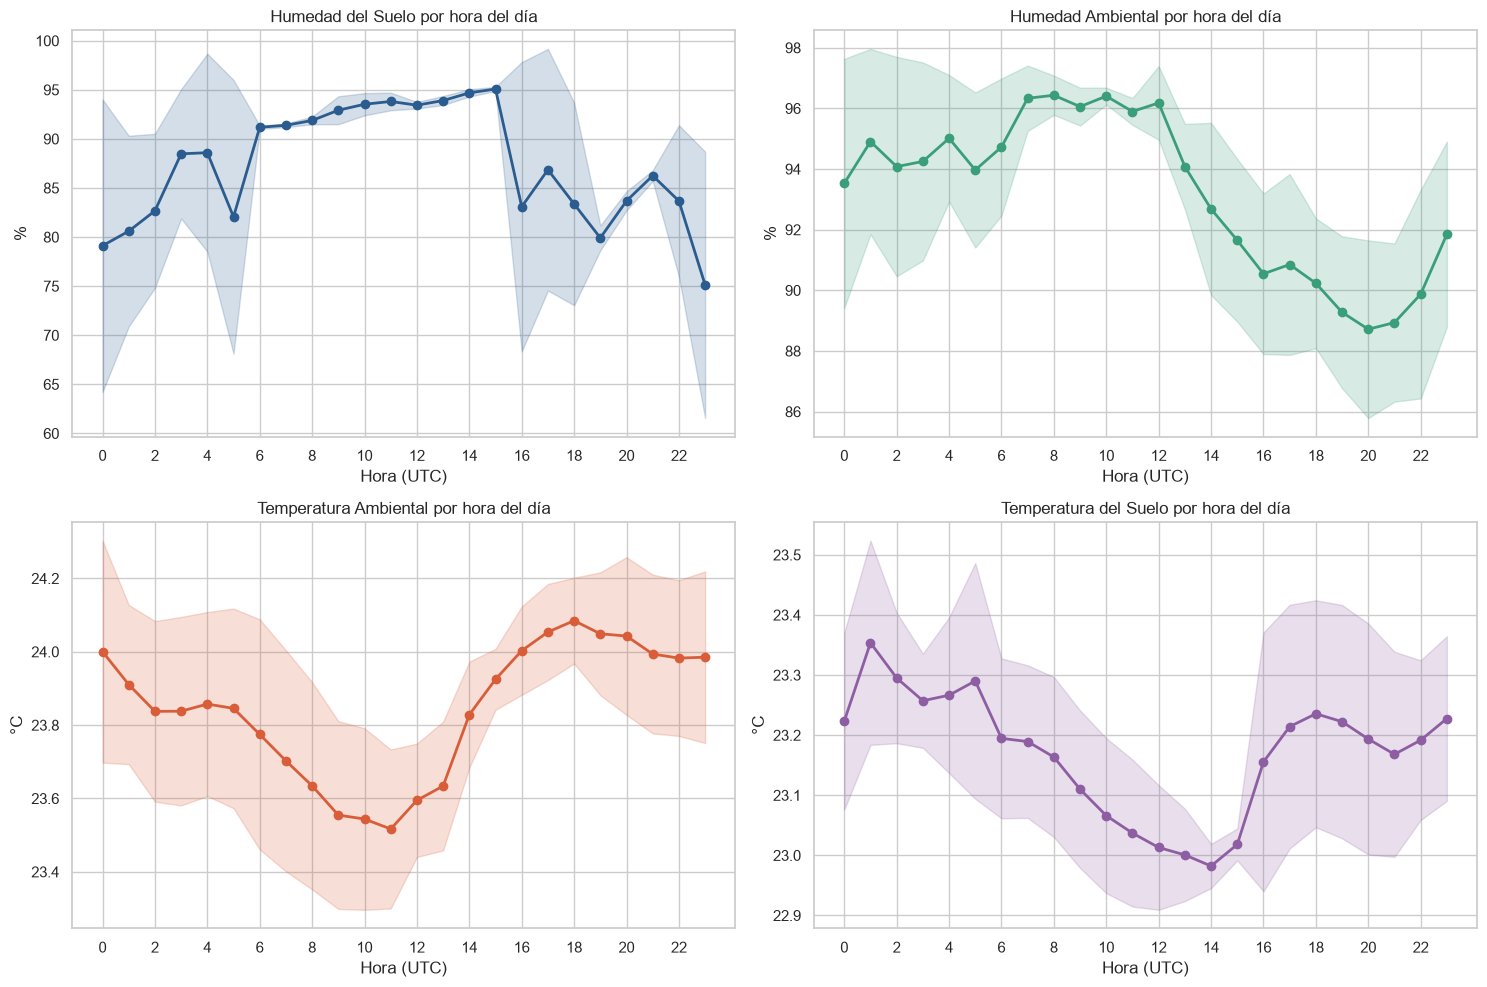

In [32]:
perfil = datos.groupby(datos.index.hour).agg(["mean", "std"])

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (tabla, cfg) in zip(axes.flat, SENSORES.items()):
    media, desv = perfil[(tabla, "mean")].dropna(), perfil[(tabla, "std")].fillna(0)
    desv = desv.reindex(media.index)
    ax.plot(media.index, media.values, color=cfg["color"], marker="o", linewidth=2)
    ax.fill_between(media.index, media - desv, media + desv, color=cfg["color"], alpha=0.2)
    ax.set_title(f"{cfg['titulo']} por hora del día", fontsize=12)
    ax.set_xlabel("Hora (UTC)")
    ax.set_ylabel(cfg["unidad"])
    ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

## 8. Correlación entre sensores

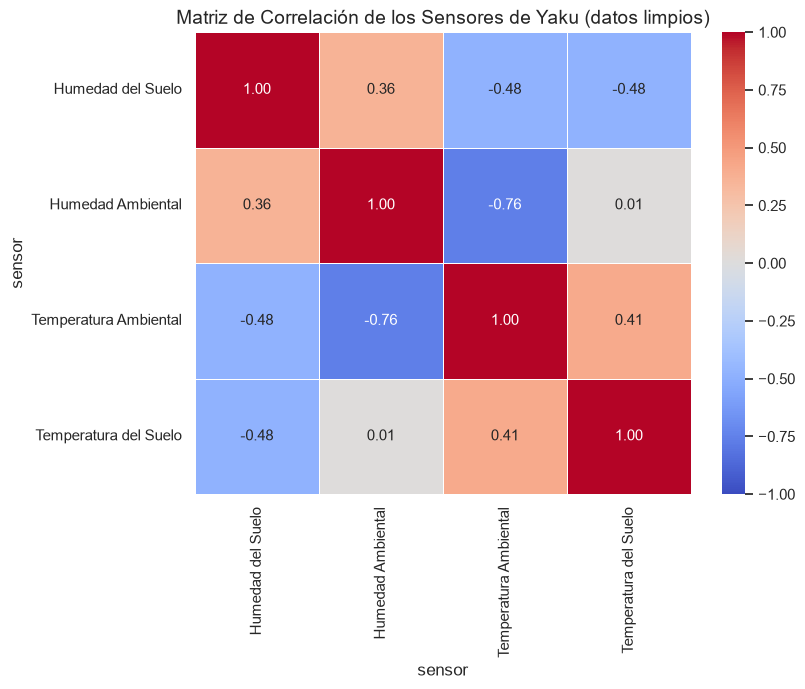

In [33]:
plt.figure(figsize=(8, 6))
sns.heatmap(datos.rename(columns=etiquetas).corr(), annot=True, cmap="coolwarm",
            fmt=".2f", linewidths=.5, vmin=-1, vmax=1)
plt.title("Matriz de Correlación de los Sensores de Yaku (datos limpios)", fontsize=14)
plt.show()

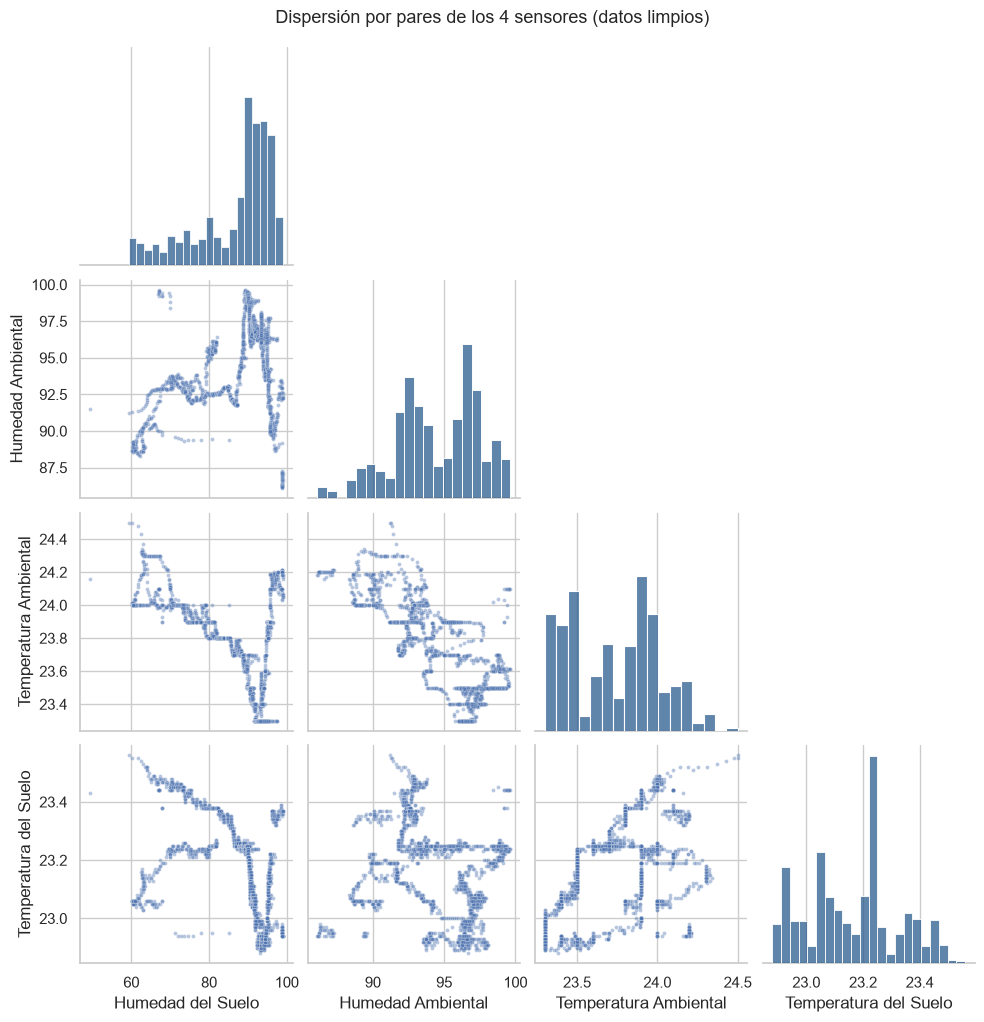

In [34]:
muestra = datos.dropna().rename(columns=etiquetas)
if len(muestra) > 2000:
    muestra = muestra.sample(2000, random_state=42)
g = sns.pairplot(muestra, corner=True, plot_kws={"s": 8, "alpha": 0.4}, diag_kws={"color": "#2b5c8f"})
g.figure.suptitle("Dispersión por pares de los 4 sensores (datos limpios)", y=1.02)
plt.show()